# 1. Dataset Prep

In [4]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [5]:
# 1. Clean the environment (the -f flag prevents errors if the file doesn't exist yet)
!rm -f names.txt*

# 2. Download a fresh, clean copy
!wget -q -O names.txt https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

In [6]:
with open('names.txt', 'r') as file:
    words = file.read().splitlines()
# How it works:
# 1. open(..., 'r') : Opens the file in read-only mode (prevents accidental edits).
# 2. .read()        : Grabs the entire file as one giant string.
# 3. .splitlines()  : Chops that string at every line break to create a clean list.

In [7]:


# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [8]:
block_size = 3

def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)

# Calculate split indices
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

# Generate the datasets
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# 2. Part 1: Raw Tensor Implementation & BatchNorm

In [9]:
n_embd = 10
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/(n_embd * block_size)**0.5 #kaiming init
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

bngain = torch.ones((1,n_hidden))
bnbias = torch.zeros((1,n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # Print total parameter count

for p in parameters:
    p.requires_grad = True

12297


In [10]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # 1. Minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # 2. Forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - hpreact.mean(0,keepdim = True)) / hpreact.std(0,keepdim = True) + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # 3. Backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # 4. Update with learning rate decay
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # 5. Track statistics
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())


      0/ 200000: 3.3147
  10000/ 200000: 2.1984
  20000/ 200000: 2.3375
  30000/ 200000: 2.4359
  40000/ 200000: 2.0119
  50000/ 200000: 2.2595
  60000/ 200000: 2.4775
  70000/ 200000: 2.1020
  80000/ 200000: 2.2788
  90000/ 200000: 2.1862
 100000/ 200000: 1.9474
 110000/ 200000: 2.3010
 120000/ 200000: 1.9837
 130000/ 200000: 2.4523
 140000/ 200000: 2.3839
 150000/ 200000: 2.1987
 160000/ 200000: 1.9733
 170000/ 200000: 1.8668
 180000/ 200000: 1.9973
 190000/ 200000: 1.8347


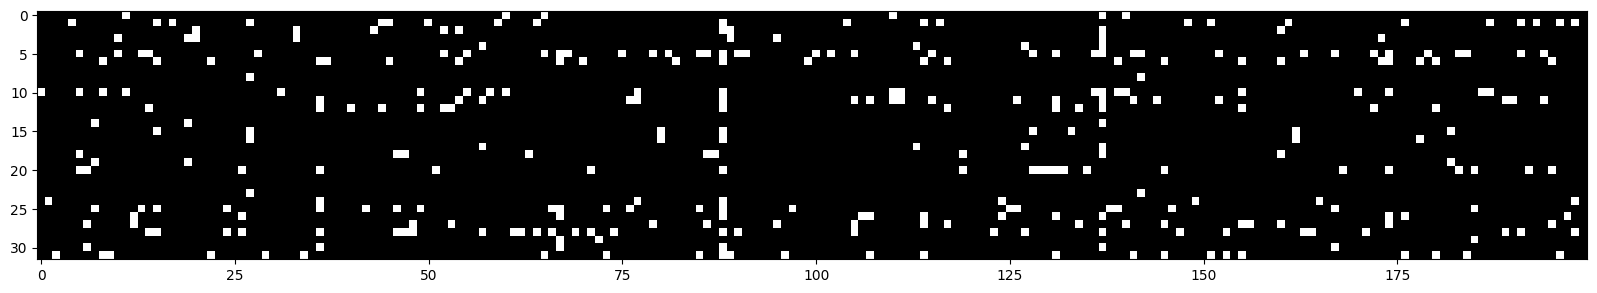

In [11]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')


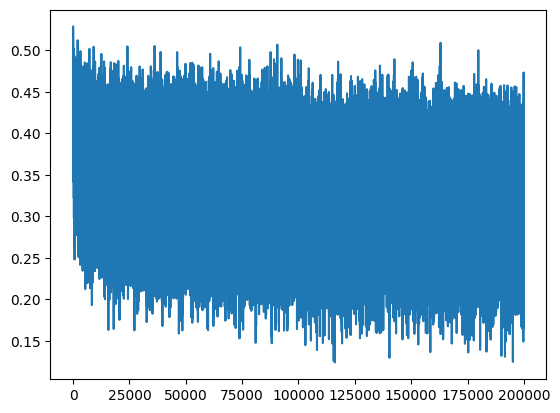

In [12]:
plt.plot(lossi) #doesnt look like a hockey stick so init was good if hockey stick then initial loss was very high ie bad init

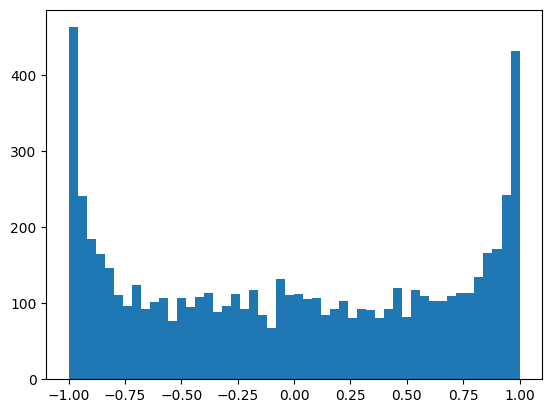

In [13]:
plt.hist(h.view(-1).tolist(),50);

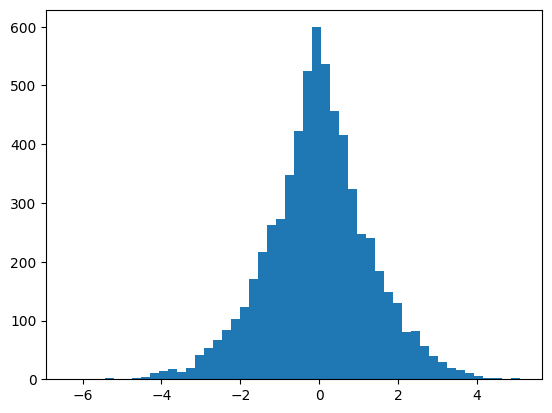

In [14]:
plt.hist(hpreact.view(-1).tolist(),50);

In [15]:
@torch.no_grad()
def split_loss(split):
    # Route to the correct dataset based on the input string
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]

    # Forward pass
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

# Execute evaluation
split_loss('train')
split_loss('val')

# NOTE: This raw implementation calculates batch stats for inference.
# Proper BatchNorm uses running buffers (fixed in Part 2)

train 2.9836857318878174
val 3.0113582611083984


In [16]:
# loss log

# original:
#train 2.1245384216308594
#val   2.168196439743042

# fix softmax confidently wrong:
#train 2.07
#val 2.13

# fix tanh layer too saturated at init:
#train 2.0355966091156006
#val 2.1026785373687744

#init is better so more productive training ie more cycles spent training
#in deeper networks, network might not train at all if init is not right

In [17]:
# Calibrate the batch norm statistics over the entire training set
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact_train = embcat @ W1 + b1
    # Measure the global mean and std
    bnmean = hpreact_train.mean(0, keepdim=True)
    bnstd = hpreact_train.std(0, keepdim=True)

In [18]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size

    while True:
        # Forward pass (Batch size 1)
        emb = C[torch.tensor([context])]
        # 1. Linear layer
        hpreact = emb.view(1, -1) @ W1 + b1
        # 2. BatchNorm layer (using the globally calibrated stats)
        hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2

        # Probability distribution & sampling
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()

        # Shift context window
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

carpahzarbriq.
shlimrixtts.
lusslaysierricnenddhn.
frtivgqliyah.
farrichaiirdnsleggyu.
bmanvitte.
sants.
lustvi.
vabbuwatth.
giidryxiidh.
sulipsables.
falia.
gtas.
jasfaylahas.
bduricsydustquovozswy.
bjumillassannyks.
sadlusoffordst.
sramsryndlycpllmanraq.
shelseombriyabhda.
ffxrdustvebndvi.


# 3. Part 2: PyTorch-like OOP Modules (Layer Classes)

In [19]:
# Let's train a deeper network

class Linear:

  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out), generator=g)
    self.bias = torch.zeros(fan_out) if bias else None

  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out

  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)

  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True, unbiased=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

# 4. OOP Network Initialization

In [20]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility

C = torch.randn((vocab_size, n_embd),            generator=g)
layers = [
  Linear(n_embd * block_size, n_hidden),BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden),BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden),BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden),BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden),BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size),
]

with torch.no_grad():
  # last layer: make less confident
  layers[-1].weight *= 0.1
  # layers[-1].gamma *= 0.1
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

47497


# 5. OOP Training Loop

In [21]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function

  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 1.0 if i < 100000 else 0.1 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
  with torch.no_grad():
    ud.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])
 # if i >= 1000:
 #   break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.3645
  10000/ 200000: 2.4711
  20000/ 200000: 2.1351
  30000/ 200000: 2.0095
  40000/ 200000: 2.3258
  50000/ 200000: 2.4231
  60000/ 200000: 1.7779
  70000/ 200000: 2.1849
  80000/ 200000: 2.3572
  90000/ 200000: 2.1185
 100000/ 200000: 2.5553
 110000/ 200000: 2.2752
 120000/ 200000: 2.0815
 130000/ 200000: 2.0087
 140000/ 200000: 1.8451
 150000/ 200000: 1.8581
 160000/ 200000: 2.0797
 170000/ 200000: 1.9900
 180000/ 200000: 2.2970
 190000/ 200000: 1.9484


# 6. OOP Evaluation

In [22]:
# Set layers to evaluation mode so BatchNorm uses running buffers, not batch statistics
for layer in layers:
  layer.training = False

# Evaluate split loss using the OOP forward pass
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]
    emb = C[x]
    x_in = emb.view(emb.shape[0], -1)
    for layer in layers:
        x_in = layer(x_in)
    loss = F.cross_entropy(x_in, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.08412766456604
val 2.12257719039917


# 7. Diagnostic Visualizations (Use only during 1,000-step debug runs)

layer 2 (      Tanh): mean -0.01, std 0.75, saturated: 23.57%
layer 5 (      Tanh): mean +0.00, std 0.76, saturated: 22.53%
layer 8 (      Tanh): mean -0.08, std 0.79, saturated: 22.08%
layer 11 (      Tanh): mean +0.01, std 0.83, saturated: 34.87%
layer 14 (      Tanh): mean +0.00, std 0.28, saturated: 0.32%


Text(0.5, 1.0, 'activation distribution')

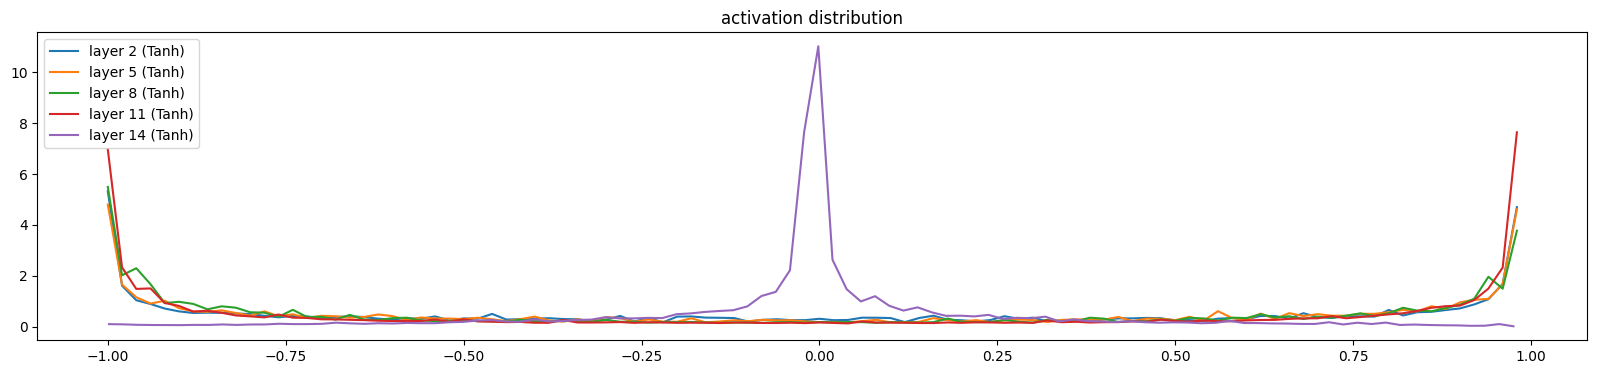

In [23]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__})')
plt.legend(legends);
plt.title('activation distribution')

In [27]:
## visualize histograms
# plt.figure(figsize=(20, 4)) # width and height of the plot
# legends = []
# for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
#   if isinstance(layer, Tanh):
#     t = layer.out.grad
#     print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
#     hy, hx = torch.histogram(t, density=True)
#     plt.plot(hx[:-1].detach(), hy.detach())
#     legends.append(f'layer {i} ({layer.__class__.__name__})')
# plt.legend(legends);
# plt.title('gradient distribution')

weight   (27, 10) | mean +0.000000 | std 4.995456e-03 | grad:data ratio 1.896095e-03
weight  (30, 100) | mean +0.000037 | std 1.837539e-03 | grad:data ratio 9.875873e-04
weight (100, 100) | mean -0.000021 | std 8.474345e-04 | grad:data ratio 5.002371e-04
weight (100, 100) | mean -0.000013 | std 8.365187e-04 | grad:data ratio 4.907163e-04
weight (100, 100) | mean -0.000012 | std 8.588318e-04 | grad:data ratio 5.073653e-04
weight (100, 100) | mean +0.000002 | std 8.033148e-04 | grad:data ratio 4.752036e-04
weight  (100, 27) | mean -0.000000 | std 7.821069e-03 | grad:data ratio 3.189064e-02


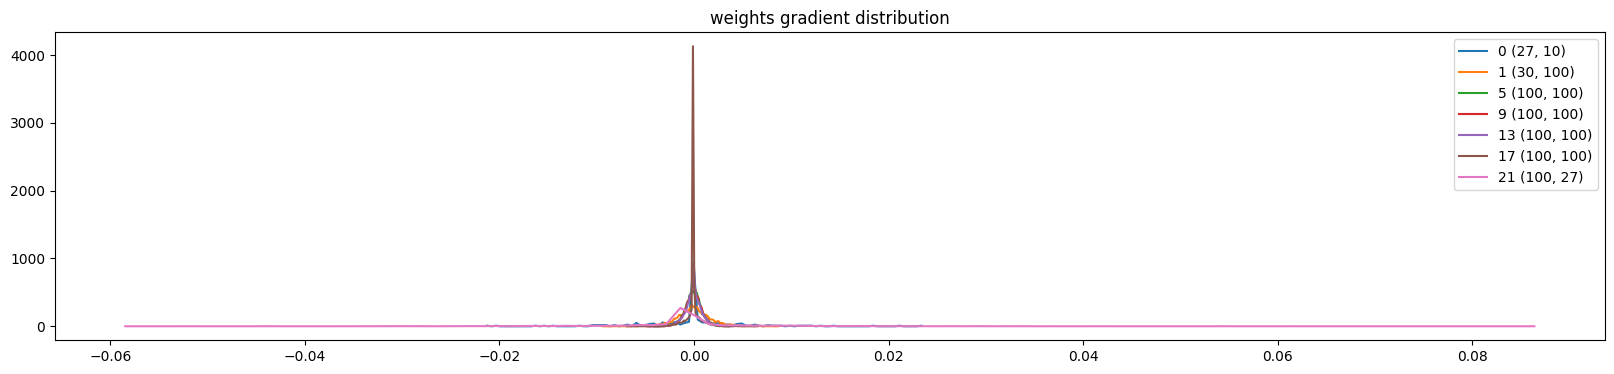

In [28]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


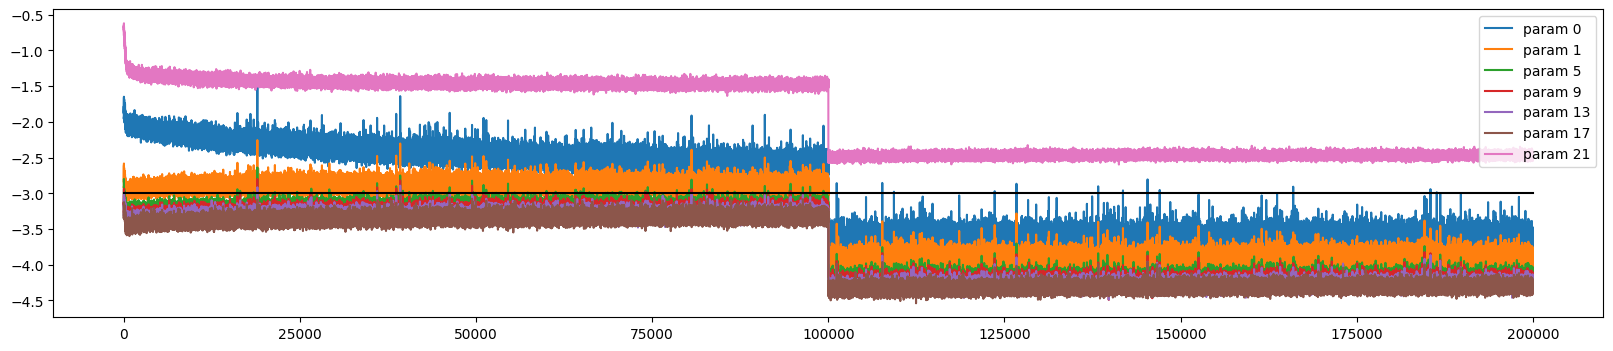

In [29]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);